In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

module_path = os.path.abspath(os.path.join('..', ''))
if module_path not in sys.path:
    sys.path.append(module_path)

from rect_prune_ood.lib.util.paths import get_top_level_path

In [2]:
severity = 1

pdf_dir = os.path.join(get_top_level_path(), 'results', 'plots')
data_dir = os.path.join(get_top_level_path(), 'results', f"percentile_mega_ablation_sev_{severity}")
percentiles = list(range(5, 105, 5))

In [3]:
all_results = []
percentile_results = {}
perturbation_results = {}

for p in percentiles:
    file_path = os.path.join(data_dir, f'percentile_{p}.csv')
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)

        df["AUROC"] = pd.to_numeric(df["AUROC"], errors="coerce")
        df["FPR"] = pd.to_numeric(df["FPR"], errors="coerce")

        avg_fpr = df["FPR"].mean()
        avg_auroc = df["AUROC"].mean()
        all_results.append({"percentile": p, "FPR": avg_fpr, "AUROC": avg_auroc})

        # Sort perturbations by highest AUROC (descending)
        df_sorted = df.sort_values(by=["AUROC", "FPR"], ascending=[False, True])
        percentile_results[p] = df_sorted[["perturbation", "AUROC", "FPR"]].values.tolist()

        if p in [85, 90, 95]:
        #if p == 85:
            for index, row in df.iterrows():
                perturbation = row["perturbation"]
                auroc = row["AUROC"]
                fpr = row["FPR"]
                if perturbation not in perturbation_results:
                    perturbation_results[perturbation] = {"AUROC": [], "FPR": []}
                perturbation_results[perturbation]["AUROC"].append(auroc)
                perturbation_results[perturbation]["FPR"].append(fpr)

# Take the average AUROC and FPR across all percentiles
# perturbation_results = {perturbation: {"AUROC": sum(aurocs) / len(aurocs), "FPR": sum(fprs) / len(fprs)}
#                         for perturbation, (aurocs, fprs) in perturbation_results.items()}
# perturbation_results = sorted(perturbation_results.items(), key=lambda x: x[1]["AUROC"], reverse=True)
        
#all_results
#percentile_results[5]
#perturbation_results

# Function to calculate average of a list
def calculate_average(values):
    return sum(values) / len(values)

# Calculating average AUROC and FPR for each perturbation
averages = {}
for perturbation, metrics in perturbation_results.items():
    avg_auroc = calculate_average(metrics['AUROC'])
    avg_fpr = calculate_average(metrics['FPR'])
    averages[perturbation] = {'avg_AUROC': avg_auroc, 'avg_FPR': avg_fpr}

averages = sorted(averages.items(), key=lambda x: x[1]['avg_AUROC'], reverse=True)
#averages

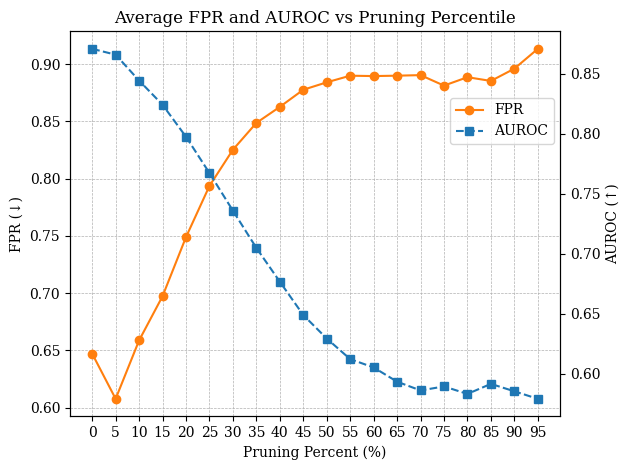

In [28]:
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Convert percentiles to pruning percentage and reverse order
percentiles = [res["percentile"] for res in all_results]
fpr_values = [res["FPR"] for res in all_results]
auroc_values = [res["AUROC"] for res in all_results]

fpr_values.reverse()
auroc_values.reverse()

# Create plot
fig, ax1 = plt.subplots()
ax1.set_xlabel("Pruning Percent (%)")
# Left y-axis for FPR, add orange dot after label to match color
ax1.set_ylabel("FPR (↓)")#, color="tab:orange")
line1, = ax1.plot(percentiles, fpr_values, marker='o', linestyle='-', color="tab:orange", label="FPR")
ax1.tick_params(axis='y')#, labelcolor="tab:orange")
ax1.set_xticks(percentiles)
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Right y-axis for AUROC
ax2 = ax1.twinx()
ax2.set_ylabel("AUROC (↑)")#, color="tab:blue")
line2, = ax2.plot(percentiles, auroc_values, marker='s', linestyle='--', color="tab:blue", label="AUROC")
ax2.tick_params(axis='y')#, labelcolor="tab:blue")

ax1.set_xticklabels(range(0, 100, 5))

plt.title("Average FPR and AUROC vs Pruning Percentile")
fig.tight_layout()
fig.legend(handles=[line1, line2], loc="upper left", bbox_to_anchor=(0.7, 0.8), ncol=1)
# Save plot
output_path = os.path.join(pdf_dir, "mega_ablation_pruning_percentile.pdf")  # Adjust as needed
plt.savefig(output_path, format="pdf")
plt.show()

/tmp/ipykernel_3514940/1534111053.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("cool")


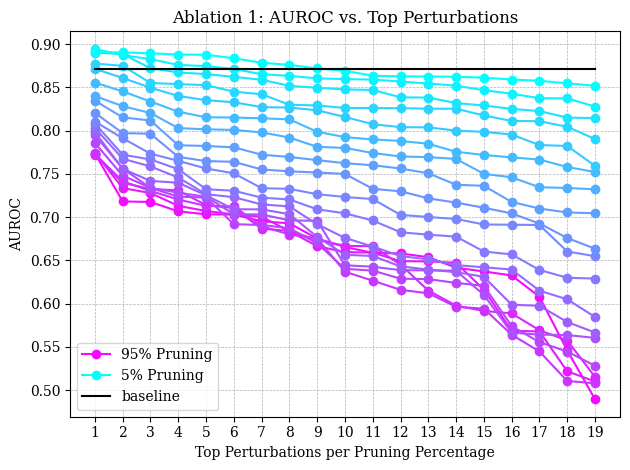

In [44]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Storage for perturbation results
percentile_results = {}

for p in percentiles:
    file_path = os.path.join(data_dir, f"percentile_{p}.csv")
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        
        # Sort perturbations by highest AUROC (descending)
        df_sorted = df.sort_values(by=["AUROC"], ascending=[False])
        percentile_results[p] = df_sorted["AUROC"].values.tolist()

# Define number of perturbations
num_perturbations = 19  # Assuming 19 perturbations
perturbation_indices = list(range(1, num_perturbations + 1))

# Create color gradient from light blue to pink
cmap = cm.get_cmap("cool")
norm = mcolors.Normalize(vmin=min(percentiles), vmax=max(percentiles))
colors = ["black" if p == 100 else cmap(norm(100 - p)) for p in percentiles]

# Create plot
fig, ax = plt.subplots()
ax.set_xlabel("Top Perturbations per Pruning Percentage")
ax.set_ylabel("AUROC")
ax.set_xticks(perturbation_indices)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# Compute cumulative averages and plot lines for each percentile
for p, color in zip(percentiles, colors):  
    # if p == 100:
    #     continue  
    if p in percentile_results:
        fpr_values = percentile_results[p]
        #cumulative_averages = [sum(auroc_values[:i]) / i for i in range(1, len(auroc_values) + 1)]
        cumulative_averages = fpr_values

        label = f"{100 - p}% Pruning" if p == 5 or p == 95 or p == 100 else None  
        if p == 100:
            label = "baseline"
        marker = None if p == 100 else 'o'
        ax.plot(perturbation_indices, cumulative_averages, marker=marker, linestyle='-', color=color, label=label)

plt.title("Ablation 1: AUROC vs. Top Perturbations")
plt.legend()
fig.tight_layout()

# Save plot
output_path = os.path.join(pdf_dir, f"ablation_pruning_auroc_sev_{severity}.pdf")  # Adjust as needed
plt.savefig(output_path, format="pdf")
plt.show()

/tmp/ipykernel_3514940/1336149358.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("cool")


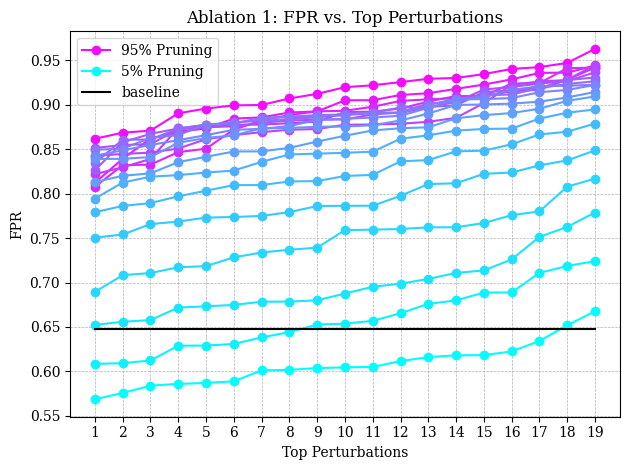

In [30]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Storage for perturbation results
percentile_results = {}

for p in percentiles:
    file_path = os.path.join(data_dir, f"percentile_{p}.csv")
    if os.path.exists(file_path):
        df = pd.read_csv(file_path)
        
        # Sort perturbations by highest FPR (ascending)
        df_sorted = df.sort_values(by=["FPR"], ascending=[True])
        percentile_results[p] = df_sorted["FPR"].values.tolist()

# Define number of perturbations
num_perturbations = 19  # Assuming 19 perturbations
perturbation_indices = list(range(1, num_perturbations + 1))

# Create color gradient from light blue to pink
cmap = cm.get_cmap("cool")
norm = mcolors.Normalize(vmin=min(percentiles), vmax=max(percentiles))
colors = ["black" if p == 100 else cmap(norm(100 - p)) for p in percentiles]

# Create plot
fig, ax = plt.subplots()
ax.set_xlabel("Top Perturbations")
ax.set_ylabel("FPR")
ax.set_xticks(perturbation_indices)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# Compute cumulative averages and plot lines for each percentile
for p, color in zip(percentiles, colors):    
    # if p == 100:
    #     continue 
    if p in percentile_results:
        fpr_values = percentile_results[p]
        cumulative_averages = [sum(fpr_values[:i]) / i for i in range(1, len(fpr_values) + 1)]
        cumulative_averages = fpr_values

        label = f"{100 - p}% Pruning" if p == 5 or p == 95  else None  
        if p == 100:
            label = "baseline"
        marker = None if p == 100 else 'o'
        ax.plot(perturbation_indices, cumulative_averages, marker=marker, linestyle='-', color=color, label=label)

plt.title("Ablation 1: FPR vs. Top Perturbations")
plt.legend()
fig.tight_layout()

# Save plot
output_path = os.path.join(pdf_dir, f"ablation_pruning_fpr_sev_{severity}.pdf")  # Adjust as needed
plt.savefig(output_path, format="pdf")
plt.show()

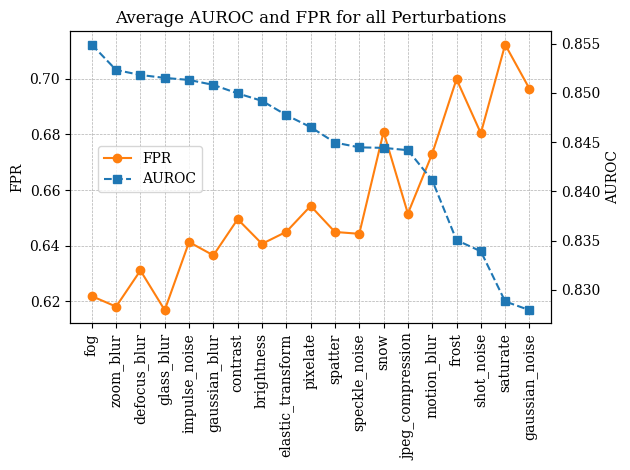

In [31]:
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Define number of perturbations
num_perturbations = 19  # Assuming 19 perturbations
perturbation_indices = list(range(1, num_perturbations + 1))

# Create plot
fig, ax1 = plt.subplots()
# ax.set_xlabel("Perturbation")
# ax.set_ylabel("Average AUROC")
# ax.set_xticks(perturbation_indices)
# ax.set_xticklabels([perturbation for perturbation, _ in averages], rotation=90)
# ax.grid(True, which='both', linestyle='--', linewidth=0.5)

auroc_values = [avg["avg_AUROC"] for _, avg in averages]
fpr_values = [avg["avg_FPR"] for _, avg in averages]

ax1.set_ylabel("FPR")#, color="tab:orange")
line1, = ax1.plot(perturbation_indices, fpr_values, marker='o', linestyle='-', color="tab:orange", label="FPR")
ax1.tick_params(axis='y')#, labelcolor="tab:orange")
ax1.set_xticks(perturbation_indices)
ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

# Right y-axis for AUROC
ax2 = ax1.twinx()
ax2.set_ylabel("AUROC")#, color="tab:blue")
line2, ax2.plot(perturbation_indices, auroc_values, marker='s', linestyle='--', color="tab:blue", label="AUROC")
ax2.tick_params(axis='y')#, labelcolor="tab:blue")

ax1.set_xticklabels([perturbation for perturbation, _ in averages], rotation=90)

fig.legend(handles=[line1, line2], loc="upper left", bbox_to_anchor=(0.15, 0.7), ncol=1)

# ax.plot(perturbation_indices, auroc_values, marker='o', linestyle='-', color='blue')
# ax.plot(perturbation_indices, fpr_values, marker='s', linestyle='--', color='orange')

plt.title("Average AUROC and FPR for all Perturbations")
#plt.legend()
fig.tight_layout()

plt.show()

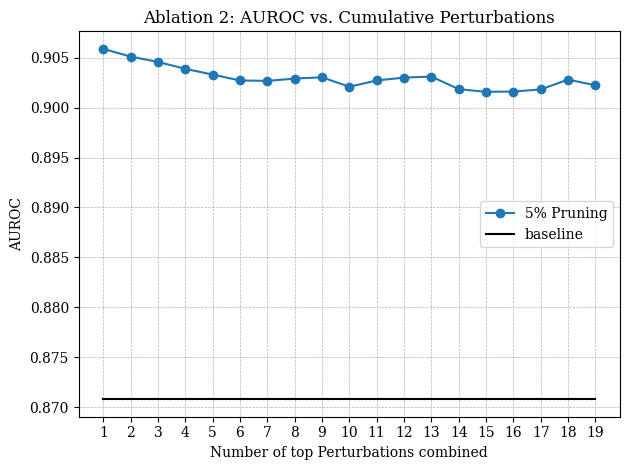

In [4]:
top_percentiles = [85, 90, 95, 100]

metric = "AUROC"

#num_perturbations_results_dir = os.path.join(get_top_level_path(), 'results', f'num_perturbations_mega_ablation_sev_{severity}')
num_perturbations_results_dir = os.path.join(get_top_level_path(), 'results', f'ablation_2_ashs_apes_sev_{severity}')

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})

# Storage for perturbation results
percentile_results = {}

for p in top_percentiles:
    if p == 100:
        continue
    file_path = os.path.join(num_perturbations_results_dir, f"percentile_{p}.csv")
    if os.path.exists(file_path):
        percentile_results[p] = pd.read_csv(file_path)[metric].values.tolist()
        
        # Sort perturbations by highest AUROC (descending)
        # df_sorted = df.sort_values(by=["AUROC"], ascending=[False])
        # percentile_results[p] = df_sorted["AUROC"].values.tolist()

percentile_results[100] = pd.read_csv(os.path.join(data_dir, "percentile_100.csv"))[metric].values.tolist()

# Define number of perturbations
num_perturbations = 19  # Assuming 19 perturbations
perturbation_indices = list(range(1, num_perturbations + 1))

# Create plot
fig, ax = plt.subplots()
ax.set_xlabel("Number of top Perturbations combined")
ax.set_ylabel(metric)
ax.set_xticks(perturbation_indices)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# Compute cumulative averages and plot lines for each percentile
for p in percentiles:  
    if p in percentile_results:
        auroc_values = percentile_results[p]
        
        if p == 100:
            ax.plot(perturbation_indices, auroc_values, marker=None, linestyle='-', label="baseline", color="black")
            continue

        ax.plot(perturbation_indices, auroc_values, marker='o', linestyle='-', label=f"{100 - p}% Pruning")

plt.title(f"Ablation 2: {metric} vs. Cumulative Perturbations")
plt.legend()
fig.tight_layout()

# Save plot
output_path = os.path.join(pdf_dir, f"ablation_pruning_auroc_sev_{severity}.pdf")  # Adjust as needed
plt.savefig(output_path, format="pdf")
plt.show()

In [38]:
sev1_p95_t2_ashs_apes = {
    'method': 'sev1_p95_t2_ashs_apes',
    'inat': {'FPR': 0.068, 'AUROC': 0.9859725029999998, 'DTERR': 0.04133333333333333, 'AUIN': 0.9970466745680711, 'AUOUT': 0.940343309404614}, 'sun': {'FPR': 0.2382, 'AUROC': 0.9491848769999999, 'DTERR': 0.07776666666666666, 'AUIN': 0.9878704068094657, 'AUOUT': 0.8286445742457398}, 'places': {'FPR': 0.3269, 'AUROC': 0.9284882909999999, 'DTERR': 0.0933, 'AUIN': 0.9826963891122011, 'AUOUT': 0.7667878348030143}, 'dtd': {'FPR': 0.17109929078014185, 'AUROC': 0.965331494680851, 'DTERR': 0.04748382458662832, 'AUIN': 0.9955851996324625, 'AUOUT': 0.820340923960388}, 'ninco': {'FPR': 0.5928887376658728, 'AUROC': 0.8518655733242599, 'DTERR': 0.0935072837252586, 'AUIN': 0.9775228770401179, 'AUOUT': 0.46231290909104694}, 'ssb_hard': {'FPR': 0.7439591836734694, 'AUROC': 0.7834682404081633, 'DTERR': 0.28854545454545455, 'AUIN': 0.7918707028220626, 'AUOUT': 0.7639103139865818}}
print_averages(sev1_p95_t2_ashs_apes)
sev1_p95_t2_ashs_apes

0.20104982269503546 0.9572442914202126


{'method': 'sev1_p95_t2_ashs_apes',
 'inat': {'FPR': 0.068,
  'AUROC': 0.9859725029999998,
  'DTERR': 0.04133333333333333,
  'AUIN': 0.9970466745680711,
  'AUOUT': 0.940343309404614},
 'sun': {'FPR': 0.2382,
  'AUROC': 0.9491848769999999,
  'DTERR': 0.07776666666666666,
  'AUIN': 0.9878704068094657,
  'AUOUT': 0.8286445742457398},
 'places': {'FPR': 0.3269,
  'AUROC': 0.9284882909999999,
  'DTERR': 0.0933,
  'AUIN': 0.9826963891122011,
  'AUOUT': 0.7667878348030143},
 'dtd': {'FPR': 0.17109929078014185,
  'AUROC': 0.965331494680851,
  'DTERR': 0.04748382458662832,
  'AUIN': 0.9955851996324625,
  'AUOUT': 0.820340923960388},
 'ninco': {'FPR': 0.5928887376658728,
  'AUROC': 0.8518655733242599,
  'DTERR': 0.0935072837252586,
  'AUIN': 0.9775228770401179,
  'AUOUT': 0.46231290909104694},
 'ssb_hard': {'FPR': 0.7439591836734694,
  'AUROC': 0.7834682404081633,
  'DTERR': 0.28854545454545455,
  'AUIN': 0.7918707028220626,
  'AUOUT': 0.7639103139865818}}

In [5]:
def print_averages(results):

    auroc_sum = 0
    fpr_sum = 0
    
    datasets = ['inat', 'sun', 'places', 'dtd']#, 'ninco', 'ssb_hard']
    
    for dataset in datasets:
        auroc_sum += results[dataset]['AUROC']
        fpr_sum += results[dataset]['FPR']

    auroc_avg = auroc_sum / len(datasets)
    fpr_avg = fpr_sum / len(datasets)

    print(fpr_avg, auroc_avg)

print_averages({'inat': {'FPR': 0.0673, 'AUROC': 0.9860389209999998, 'DTERR': 0.0408, 'AUIN': 0.9970417948958791, 'AUOUT': 0.9412412155454991}, 'sun': {'FPR': 0.2517, 'AUROC': 0.946813211, 'DTERR': 0.08038333333333333, 'AUIN': 0.9872479043147535, 'AUOUT': 0.8246794761385259}, 'places': {'FPR': 0.3468, 'AUROC': 0.9237703340000001, 'DTERR': 0.0982, 'AUIN': 0.9815137010583114, 'AUOUT': 0.7577181335294825}, 'dtd': {'FPR': 0.16046099290780141, 'AUROC': 0.9676047464539007, 'DTERR': 0.0450215672178289, 'AUIN': 0.9958777480126493, 'AUOUT': 0.8329353892714388}, 'ninco': {'FPR': 0.6184076216400136, 'AUROC': 0.835315250085063, 'DTERR': 0.0945273631840796, 'AUIN': 0.9741615194771143, 'AUOUT': 0.4425568134023021}, 'ssb_hard': {'FPR': 0.7544285714285714, 'AUROC': 0.7742534597959183, 'DTERR': 0.2962727272727273, 'AUIN': 0.7821547656995886, 'AUOUT': 0.7558797003217312}})

0.20656524822695033 0.9560568031134752


In [41]:
sev_p95_t1_ashs_apes = {'inat': {'FPR': 0.0659, 'AUROC': 0.9864991409999999, 'DTERR': 0.039983333333333336, 'AUIN': 0.9971451608376134, 'AUOUT': 0.9430984678301086}, 'sun': {'FPR': 0.2572, 'AUROC': 0.9460329390000001, 'DTERR': 0.08108333333333333, 'AUIN': 0.9871847053633725, 'AUOUT': 0.8198738565488408}, 'places': {'FPR': 0.3541, 'AUROC': 0.9235009980000001, 'DTERR': 0.09795, 'AUIN': 0.9815425860387159, 'AUOUT': 0.7529876626933398}, 'dtd': {'FPR': 0.16914893617021276, 'AUROC': 0.9657514202127659, 'DTERR': 0.04681883537023724, 'AUIN': 0.995629820761688, 'AUOUT': 0.82413076379162}, 'ninco': {'FPR': 0.5923783599863899, 'AUROC': 0.8502360632868322, 'DTERR': 0.09373993342639321, 'AUIN': 0.9771195613082566, 'AUOUT': 0.4628579079923031}, 'ssb_hard': {'FPR': 0.7361020408163266, 'AUROC': 0.7844129604081632, 'DTERR': 0.28835353535353536, 'AUIN': 0.7913906377390975, 'AUOUT': 0.7669964948756659}}

print_averages(sev_p95_t1_ashs_apes)
sev_p95_t1_ashs_apes

0.2115872340425532 0.9554461245531916


{'inat': {'FPR': 0.0659,
  'AUROC': 0.9864991409999999,
  'DTERR': 0.039983333333333336,
  'AUIN': 0.9971451608376134,
  'AUOUT': 0.9430984678301086},
 'sun': {'FPR': 0.2572,
  'AUROC': 0.9460329390000001,
  'DTERR': 0.08108333333333333,
  'AUIN': 0.9871847053633725,
  'AUOUT': 0.8198738565488408},
 'places': {'FPR': 0.3541,
  'AUROC': 0.9235009980000001,
  'DTERR': 0.09795,
  'AUIN': 0.9815425860387159,
  'AUOUT': 0.7529876626933398},
 'dtd': {'FPR': 0.16914893617021276,
  'AUROC': 0.9657514202127659,
  'DTERR': 0.04681883537023724,
  'AUIN': 0.995629820761688,
  'AUOUT': 0.82413076379162},
 'ninco': {'FPR': 0.5923783599863899,
  'AUROC': 0.8502360632868322,
  'DTERR': 0.09373993342639321,
  'AUIN': 0.9771195613082566,
  'AUOUT': 0.4628579079923031},
 'ssb_hard': {'FPR': 0.7361020408163266,
  'AUROC': 0.7844129604081632,
  'DTERR': 0.28835353535353536,
  'AUIN': 0.7913906377390975,
  'AUOUT': 0.7669964948756659}}

In [39]:
sev1_p95_all_ashs_apes = {'inat': {'FPR': 0.0729, 'AUROC': 0.9854199949999999, 'DTERR': 0.04281666666666667, 'AUIN': 0.9969456618717442, 'AUOUT': 0.9377400802302398}, 'sun': {'FPR': 0.216, 'AUROC': 0.955441986, 'DTERR': 0.07406666666666667, 'AUIN': 0.989690376201724, 'AUOUT': 0.8451211294151595}, 'places': {'FPR': 0.2998, 'AUROC': 0.934943575, 'DTERR': 0.08948333333333333, 'AUIN': 0.9843914504179422, 'AUOUT': 0.784571311493359}, 'dtd': {'FPR': 0.1700354609929078, 'AUROC': 0.9661918138297872, 'DTERR': 0.047753414809489574, 'AUIN': 0.9957248966716563, 'AUOUT': 0.822473276154912}, 'ninco': {'FPR': 0.5911874787342634, 'AUROC': 0.8508660343654305, 'DTERR': 0.09377572568810623, 'AUIN': 0.9773738765313593, 'AUOUT': 0.46196077626159926}, 'ssb_hard': {'FPR': 0.7550204081632653, 'AUROC': 0.779999776122449, 'DTERR': 0.29054545454545455, 'AUIN': 0.7904594083236929, 'AUOUT': 0.7583909306874655}}
print_averages(sev1_p95_all_ashs_apes)
sev1_p95_all_ashs_apes

0.18968386524822695 0.9604993424574468


{'inat': {'FPR': 0.0729,
  'AUROC': 0.9854199949999999,
  'DTERR': 0.04281666666666667,
  'AUIN': 0.9969456618717442,
  'AUOUT': 0.9377400802302398},
 'sun': {'FPR': 0.216,
  'AUROC': 0.955441986,
  'DTERR': 0.07406666666666667,
  'AUIN': 0.989690376201724,
  'AUOUT': 0.8451211294151595},
 'places': {'FPR': 0.2998,
  'AUROC': 0.934943575,
  'DTERR': 0.08948333333333333,
  'AUIN': 0.9843914504179422,
  'AUOUT': 0.784571311493359},
 'dtd': {'FPR': 0.1700354609929078,
  'AUROC': 0.9661918138297872,
  'DTERR': 0.047753414809489574,
  'AUIN': 0.9957248966716563,
  'AUOUT': 0.822473276154912},
 'ninco': {'FPR': 0.5911874787342634,
  'AUROC': 0.8508660343654305,
  'DTERR': 0.09377572568810623,
  'AUIN': 0.9773738765313593,
  'AUOUT': 0.46196077626159926},
 'ssb_hard': {'FPR': 0.7550204081632653,
  'AUROC': 0.779999776122449,
  'DTERR': 0.29054545454545455,
  'AUIN': 0.7904594083236929,
  'AUOUT': 0.7583909306874655}}

In [11]:
sev5_p90_t6_apes = {
    'method': 'sev5_p90_t6_apes',
    'inat': {'FPR': 0.1033, 'AUROC': 0.978318612, 'DTERR': 0.04741666666666667, 'AUIN': 0.9949710287297596, 'AUOUT': 0.9251343542105871}, 
    'sun': {'FPR': 0.4022, 'AUROC': 0.9063988310000001, 'DTERR': 0.1067, 'AUIN': 0.9763448097865993, 'AUOUT': 0.7140322942604111}, 
    'places': {'FPR': 0.4934, 'AUROC': 0.883803768, 'DTERR': 0.12296666666666667, 'AUIN': 0.971253682958552, 'AUOUT': 0.6446827206627078}, 
    'dtd': {'FPR': 0.4602836879432624, 'AUROC': 0.8787106170212766, 'DTERR': 0.08075125808770668, 'AUIN': 0.9803431707260086, 'AUOUT': 0.5706224424463007}, 
    'ninco': {'FPR': 0.6502211636611093, 'AUROC': 0.8220065243280028, 'DTERR': 0.09628118400801747, 'AUIN': 0.9728444911901526, 'AUOUT': 0.4134844222590168}, 
    'ssb_hard': {'FPR': 0.7615918367346939, 'AUROC': 0.7466733695918367, 'DTERR': 0.31922222222222224, 'AUIN': 0.745467192662764, 'AUOUT': 0.7379812618975845}
}

print_averages(sev5_p90_t6_apes)

0.3647959219858156 0.9118079570053191


In [12]:
sev5_p90_t6_ashs_apes = {
    'method': 'sev5_p90_t6_ashs_apes',
    'inat': {'FPR': 0.0486, 'AUROC': 0.989683606, 'DTERR': 0.034866666666666664, 'AUIN': 0.9978186480967315, 'AUOUT': 0.9564756010308124}, 
    'sun': {'FPR': 0.2636, 'AUROC': 0.9460692349999998, 'DTERR': 0.08283333333333333, 'AUIN': 0.9872754227923793, 'AUOUT': 0.8145259308221251}, 
    'places': {'FPR': 0.3692, 'AUROC': 0.9202489060000001, 'DTERR': 0.10308333333333333, 'AUIN': 0.9808459954216349, 'AUOUT': 0.7376582798091313}, 
    'dtd': {'FPR': 0.13882978723404255, 'AUROC': 0.9721266737588653, 'DTERR': 0.042235801581595976, 'AUIN': 0.9965106184568864, 'AUOUT': 0.8524747057047862}, 
    'ninco': {'FPR': 0.6167063627084042, 'AUROC': 0.8429796461381422, 'DTERR': 0.09382941408067576, 'AUIN': 0.9757700469860573, 'AUOUT': 0.45286904895342645}, 
    'ssb_hard': {'FPR': 0.790795918367347, 'AUROC': 0.7585455210204082, 'DTERR': 0.30766666666666664, 'AUIN': 0.7699347892938331, 'AUOUT': 0.7362375019460748}
}

print_averages(sev5_p90_t6_ashs_apes)
sev5_p90_t6_ashs_apes


0.20505744680851062 0.9570321051897163


{'method': 'sev5_p90_t6_ashs_apes',
 'inat': {'FPR': 0.0486,
  'AUROC': 0.989683606,
  'DTERR': 0.034866666666666664,
  'AUIN': 0.9978186480967315,
  'AUOUT': 0.9564756010308124},
 'sun': {'FPR': 0.2636,
  'AUROC': 0.9460692349999998,
  'DTERR': 0.08283333333333333,
  'AUIN': 0.9872754227923793,
  'AUOUT': 0.8145259308221251},
 'places': {'FPR': 0.3692,
  'AUROC': 0.9202489060000001,
  'DTERR': 0.10308333333333333,
  'AUIN': 0.9808459954216349,
  'AUOUT': 0.7376582798091313},
 'dtd': {'FPR': 0.13882978723404255,
  'AUROC': 0.9721266737588653,
  'DTERR': 0.042235801581595976,
  'AUIN': 0.9965106184568864,
  'AUOUT': 0.8524747057047862},
 'ninco': {'FPR': 0.6167063627084042,
  'AUROC': 0.8429796461381422,
  'DTERR': 0.09382941408067576,
  'AUIN': 0.9757700469860573,
  'AUOUT': 0.45286904895342645},
 'ssb_hard': {'FPR': 0.790795918367347,
  'AUROC': 0.7585455210204082,
  'DTERR': 0.30766666666666664,
  'AUIN': 0.7699347892938331,
  'AUOUT': 0.7362375019460748}}

In [13]:
sev5_p90_t6_scale_apes = {
    'method': 'sev5_p90_t6_scale',
    'inat': {'FPR': 0.0542, 'AUROC': 0.9887530499999999, 'DTERR': 0.03643333333333333, 'AUIN': 0.9976113219448904, 'AUOUT': 0.9531501747121394}, 
    'sun': {'FPR': 0.232, 'AUROC': 0.9515497700000001, 'DTERR': 0.07703333333333333, 'AUIN': 0.9886192484264141, 'AUOUT': 0.8341392299502126}, 
    'places': {'FPR': 0.3351, 'AUROC': 0.9263541070000001, 'DTERR': 0.09605, 'AUIN': 0.9822042335352859, 'AUOUT': 0.7603900889970631}, 
    'dtd': {'FPR': 0.15638297872340426, 'AUROC': 0.9684246932624114, 'DTERR': 0.04520129403306974, 'AUIN': 0.9960318457531789, 'AUOUT': 0.8366809864421847}, 
    'ninco': {'FPR': 0.6182374957468527, 'AUROC': 0.83498539809459, 'DTERR': 0.09436629800637102, 'AUIN': 0.9738112498816969, 'AUOUT': 0.44597863372305097}, 
    'ssb_hard': {'FPR': 0.7772653061224489, 'AUROC': 0.7703601406122449, 'DTERR': 0.29667676767676765, 'AUIN': 0.7807344058836146, 'AUOUT': 0.7477425475551274}
}

print_averages(sev5_p90_t6_scale_apes)

0.19442074468085105 0.958770405065603


In [14]:
sev5_p95_custom_apes = {
    'method': 'sev5_p95_custom_apes',
    'inat': {'FPR': 0.2648, 'AUROC': 0.949356267, 'DTERR': 0.08378333333333333, 'AUIN': 0.9886000092584816, 'AUOUT': 0.8179888650642595}, 
    'sun': {'FPR': 0.3718, 'AUROC': 0.9112767169999999, 'DTERR': 0.10068333333333333, 'AUIN': 0.9770077707018268, 'AUOUT': 0.7531406634689309}, 
    'places': {'FPR': 0.4563, 'AUROC': 0.8907668470000001, 'DTERR': 0.11571666666666666, 'AUIN': 0.9725142091177069, 'AUOUT': 0.6874878381196259}, 
    'dtd': {'FPR': 0.5331560283687943, 'AUROC': 0.8589009024822696, 'DTERR': 0.08583752695902229, 'AUIN': 0.97704788685332, 'AUOUT': 0.5178799196236555}, 
    'ninco': {'FPR': 0.681524328002722, 'AUROC': 0.8161820551207896, 'DTERR': 0.09944879916961953, 'AUIN': 0.972165385159218, 'AUOUT': 0.3827516105138107}, 
    'ssb_hard': {'FPR': 0.7518163265306123, 'AUROC': 0.7522800908163266, 'DTERR': 0.31504040404040407, 'AUIN': 0.7509799725506462, 'AUOUT': 0.7432977109929134}
}

print_averages(sev5_p95_custom_apes)


0.40651400709219854 0.9025751833705674


In [15]:
sev5_p95_custom_ashs_apes = {
    'method': 'sev5_p95_custom_ashs_apes',
    'inat': {'FPR': 0.0832, 'AUROC': 0.984025328, 'DTERR': 0.04418333333333333, 'AUIN': 0.99660945454763, 'AUOUT': 0.934138483968116}, 
    'sun': {'FPR': 0.2305, 'AUROC': 0.951040953, 'DTERR': 0.07635, 'AUIN': 0.9882109054892496, 'AUOUT': 0.8377711558046118}, 
    'places': {'FPR': 0.3314, 'AUROC': 0.926148524, 'DTERR': 0.09575, 'AUIN': 0.9819706574277944, 'AUOUT': 0.7657508843383324}, 
    'dtd': {'FPR': 0.14397163120567377, 'AUROC': 0.9718267641843972, 'DTERR': 0.04293673616103522, 'AUIN': 0.9964674806920197, 'AUOUT': 0.8505174045497098}, 
    'ninco': {'FPR': 0.6146648519904729, 'AUROC': 0.8402941459680164, 'DTERR': 0.09467053223093168, 'AUIN': 0.9752541163567876, 'AUOUT': 0.44741508724542767}, 
    'ssb_hard': {'FPR': 0.7738571428571429, 'AUROC': 0.7645753069387756, 'DTERR': 0.30434343434343436, 'AUIN': 0.7758960814419893, 'AUOUT': 0.7432416656690736}
}


print_averages(sev5_p95_custom_ashs_apes)

0.19726790780141845 0.9582603922960994


In [16]:
sev1_p95_custom_ashs_apes = {
    'method': 'sev1_p95_custom_ashs_apes',
    'inat': {'FPR': 0.0775, 'AUROC': 0.984685691, 'DTERR': 0.04351666666666667, 'AUIN': 0.9967721298288017, 'AUOUT': 0.9357546853204978}, 
    'sun': {'FPR': 0.202, 'AUROC': 0.9582395170000001, 'DTERR': 0.07163333333333333, 'AUIN': 0.9904020578700161, 'AUOUT': 0.8546896580057513}, 
    'places': {'FPR': 0.2786, 'AUROC': 0.9383949530000001, 'DTERR': 0.08545, 'AUIN': 0.9851719462963866, 'AUOUT': 0.7981577385221984}, 
    'dtd': {'FPR': 0.1698581560283688, 'AUROC': 0.9661556471631205, 'DTERR': 0.04786125089863408, 'AUIN': 0.9957129508509495, 'AUOUT': 0.8219520817162531}, 
    'ninco': {'FPR': 0.5993535216059884, 'AUROC': 0.8479834994896225, 'DTERR': 0.09416944056694942, 'AUIN': 0.9769169777183959, 'AUOUT': 0.4564980200557022}, 'ssb_hard': {'FPR': 0.7461428571428571, 'AUROC': 0.783734888367347, 'DTERR': 0.2880707070707071, 'AUIN': 0.793088562256259, 'AUOUT': 0.7632932745384035}
}

print_averages(sev1_p95_custom_ashs_apes)

0.1819895390070922 0.9618689520407802


In [17]:
sev1_p85_t3_ashs_apes = {
    'method': 'sev1_p85_t3_ashs_apes',
    'inat': {'FPR': 0.0837, 'AUROC': 0.983118218, 'DTERR': 0.044283333333333334, 'AUIN': 0.9963915743856646, 'AUOUT': 0.9313595562321303}, 
    'sun': {'FPR': 0.1969, 'AUROC': 0.9597385970000001, 'DTERR': 0.07071666666666666, 'AUIN': 0.9908900043431574, 'AUOUT': 0.8587877868283438}, 
    'places': {'FPR': 0.2645, 'AUROC': 0.942216009, 'DTERR': 0.08303333333333333, 'AUIN': 0.9860540822041204, 'AUOUT': 0.8088623873489535}, 
    'dtd': {'FPR': 0.25656028368794326, 'AUROC': 0.9483699468085105, 'DTERR': 0.059507548526240114, 'AUIN': 0.9933184222364961, 'AUOUT': 0.7438836163156659}, 
    'ninco': {'FPR': 0.6075195644777135, 'AUROC': 0.8416867471929227, 'DTERR': 0.09520741615662694, 'AUIN': 0.9756785923719553, 'AUOUT': 0.4466680873210493}, 'ssb_hard': {'FPR': 0.7186938775510204, 'AUROC': 0.7982460865306122, 'DTERR': 0.27546464646464647, 'AUIN': 0.8064132479176418, 'AUOUT': 0.7790942517644145}
}

print_averages(sev1_p85_t3_ashs_apes)

0.2004150709219858 0.9583606927021275


In [18]:
sev1_p90_t6_ashs_apes = {
    'method': 'sev1_p90_t6_ashs_apes',
    'inat': {'FPR': 0.0804, 'AUROC': 0.9833107189999999, 'DTERR': 0.045483333333333334, 'AUIN': 0.9964709110339908, 'AUOUT': 0.929499018182229}, 
    'sun': {'FPR': 0.196, 'AUROC': 0.959942738, 'DTERR': 0.07035, 'AUIN': 0.9908904169332409, 'AUOUT': 0.8596154437049964}, 
    'places': {'FPR': 0.2591, 'AUROC': 0.942366749, 'DTERR': 0.08223333333333334, 'AUIN': 0.9861189966860071, 'AUOUT': 0.8103414873433276}, 
    'dtd': {'FPR': 0.21347517730496454, 'AUROC': 0.9566606755319149, 'DTERR': 0.05384615384615385, 'AUIN': 0.9944408295217086, 'AUOUT': 0.7802187283354398}, 
    'ninco': {'FPR': 0.6156856073494386, 'AUROC': 0.8393554797550187, 'DTERR': 0.09604853430688286, 'AUIN': 0.9752435513179308, 'AUOUT': 0.4377429340288924}, 'ssb_hard': {'FPR': 0.7243877551020408, 'AUROC': 0.7959785355102041, 'DTERR': 0.2777979797979798, 'AUIN': 0.8048741796135437, 'AUOUT': 0.7757849774929907}
}

print_averages(sev1_p90_t6_ashs_apes)

0.18724379432624114 0.9605702203829787


In [19]:
sev1_p95_t1_ashs_apes = {
    'method': 'sev1_p95_t1_ashs_apes',
    'inat': {'FPR': 0.0692, 'AUROC': 0.9858860949999999, 'DTERR': 0.04161666666666667, 'AUIN': 0.997028976248163, 'AUOUT': 0.9399881490189529}, 'dtd': {'FPR': 0.1702127659574468, 'AUROC': 0.9655066010638298, 'DTERR': 0.047465851905104245, 'AUIN': 0.9956100069384015, 'AUOUT': 0.8209002681547541}, 'sun': {'FPR': 0.2221, 'AUROC': 0.9527617339999999, 'DTERR': 0.0754, 'AUIN': 0.9888122497786589, 'AUOUT': 0.8395947585891019}, 'places': {'FPR': 0.3079, 'AUROC': 0.932531977, 'DTERR': 0.09068333333333334, 'AUIN': 0.9837082485231257, 'AUOUT': 0.7793666037777855}, 'ninco': {'FPR': 0.594760122490643, 'AUROC': 0.849837313712147, 'DTERR': 0.09365045277211068, 'AUIN': 0.9771458302995568, 'AUOUT': 0.46088220391679163}, 'ssb_hard': {'FPR': 0.7428979591836735, 'AUROC': 0.7851729514285715, 'DTERR': 0.28704040404040404, 'AUIN': 0.7941625486627341, 'AUOUT': 0.7652680021219883}
    }

print_averages(sev1_p95_t1_ashs_apes)

0.1923531914893617 0.9591716017659574


In [20]:
sev1_p90_t1_ashs_apes = {
    'method': 'sev1_p90_t1_ashs_apes',
    'inat': {'FPR': 0.0763, 'AUROC': 0.984258503, 'DTERR': 0.044033333333333334, 'AUIN': 0.9966739456477373, 'AUOUT': 0.9340740924822363}, 
    'sun': {'FPR': 0.1917, 'AUROC': 0.9604682420000001, 'DTERR': 0.06973333333333333, 'AUIN': 0.9910325933157307, 'AUOUT': 0.8612845552505887}, 
    'places': {'FPR': 0.2597, 'AUROC': 0.9419528009999999, 'DTERR': 0.0824, 'AUIN': 0.9860215594671013, 'AUOUT': 0.8099923453022846}, 
    'dtd': {'FPR': 0.2127659574468085, 'AUROC': 0.9564880460992908, 'DTERR': 0.05348670021567218, 'AUIN': 0.9944124366946008, 'AUOUT': 0.780535083148521}, 
    'ninco': {'FPR': 0.6146648519904729, 'AUROC': 0.8381543399115345, 'DTERR': 0.0953326890726225, 'AUIN': 0.9751087849970419, 'AUOUT': 0.44009914576152265}, 'ssb_hard': {'FPR': 0.7343061224489796, 'AUROC': 0.7880050146938776, 'DTERR': 0.2845151515151515, 'AUIN': 0.7965515099642896, 'AUOUT': 0.7682580027741308}
}

print_averages(sev1_p90_t1_ashs_apes)

0.18511648936170214 0.9607918980248227


In [21]:
sev1_p85_t1_ashs_apes = {
    'method': 'sev1_p85_t1_ashs_apes',
    'inat': {'FPR': 0.0878, 'AUROC': 0.9825434399999999, 'DTERR': 0.045366666666666666, 'AUIN': 0.9962773307873919, 'AUOUT': 0.9283733470033488}, 
    'sun': {'FPR': 0.195, 'AUROC': 0.9597290909999999, 'DTERR': 0.07053333333333334, 'AUIN': 0.9908919545714171, 'AUOUT': 0.8580704257525932}, 
    'places': {'FPR': 0.2605, 'AUROC': 0.943107799, 'DTERR': 0.08248333333333334, 'AUIN': 0.9863265508642312, 'AUOUT': 0.8097120864522054}, 
    'dtd': {'FPR': 0.2542553191489362, 'AUROC': 0.9484243882978725, 'DTERR': 0.06002875629043854, 'AUIN': 0.9933302247361856, 'AUOUT': 0.7418978881197892}, 
    'ninco': {'FPR': 0.5939094930248384, 'AUROC': 0.8453033787002382, 'DTERR': 0.09483159740864025, 'AUIN': 0.9762848753359685, 'AUOUT': 0.4528181916547138}, 'ssb_hard': {'FPR': 0.7119795918367346, 'AUROC': 0.8058805904081632, 'DTERR': 0.2684343434343434, 'AUIN': 0.8145002811698807, 'AUOUT': 0.7854184390966454}
}

print_averages(sev1_p85_t1_ashs_apes)


0.19938882978723405 0.9584511795744681


In [22]:
sev1_p90_t1_apes = {
    'method': 'sev1_p90_t1_apes',
    'inat': {'FPR': 0.274, 'AUROC': 0.9495721610000001, 'DTERR': 0.08528333333333334, 'AUIN': 0.9889403941125233, 'AUOUT': 0.8160433536511265}, 
    'sun': {'FPR': 0.2721, 'AUROC': 0.932711213, 'DTERR': 0.0827, 'AUIN': 0.9822479326256308, 'AUOUT': 0.8146311756689941}, 
    'places': {'FPR': 0.3173, 'AUROC': 0.923471108, 'DTERR': 0.09145, 'AUIN': 0.9803640985778386, 'AUOUT': 0.7787486479566726}, 
    'dtd': {'FPR': 0.7171985815602837, 'AUROC': 0.7785146578014184, 'DTERR': 0.09548885693745507, 'AUIN': 0.9633427048701297, 'AUOUT': 0.347147831413701}, 
    'ninco': {'FPR': 0.7196325280707724, 'AUROC': 0.809518011228309, 'DTERR': 0.10048677475929704, 'AUIN': 0.9715523737873977, 'AUOUT': 0.3563410920902342}, 'ssb_hard': {'FPR': 0.702265306122449, 'AUROC': 0.7795503957142859, 'DTERR': 0.29303030303030303, 'AUIN': 0.7748478176196452, 'AUOUT': 0.773256982836591}
}

print_averages(sev1_p90_t1_apes)

0.3951496453900709 0.8960672849503546


In [23]:
sev1_p85_t3_apes = {
    'method': 'sev1_p85_t3_apes',
    'inat': {'FPR': 0.257, 'AUROC': 0.9522730410000001, 'DTERR': 0.0817, 'AUIN': 0.9895032496894535, 'AUOUT': 0.8256703533561138}, 
    'sun': {'FPR': 0.2681, 'AUROC': 0.933054046, 'DTERR': 0.08125, 'AUIN': 0.9821942706133416, 'AUOUT': 0.81640865395177}, 
    'places': {'FPR': 0.3069, 'AUROC': 0.9253637650000001, 'DTERR': 0.09035, 'AUIN': 0.9808610570609831, 'AUOUT': 0.7821350409178841}, 
    'dtd': {'FPR': 0.7659574468085106, 'AUROC': 0.7435583971631206, 'DTERR': 0.09676491732566499, 'AUIN': 0.9577519123248024, 'AUOUT': 0.29931285992237855}, 
    'ninco': {'FPR': 0.6862878530112283, 'AUROC': 0.8174974038788704, 'DTERR': 0.1001825405347364, 'AUIN': 0.9727100036751538, 'AUOUT': 0.372670493277109}, 'ssb_hard': {'FPR': 0.6664897959183673, 'AUROC': 0.7943244173469388, 'DTERR': 0.2801818181818182, 'AUIN': 0.7858451461955447, 'AUOUT': 0.7906544700778708}
}

print_averages(sev1_p85_t3_apes)

0.3994893617021277 0.8885623122907802


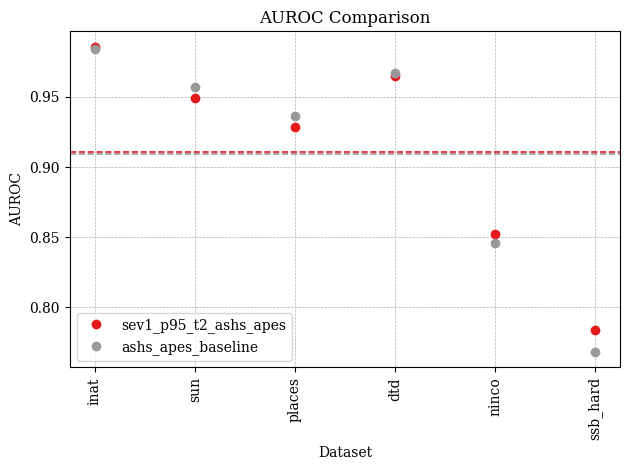

In [36]:
import matplotlib.pyplot as plt
import numpy as np

ashs_apes_baseline = {
    'method': 'ashs_apes_baseline',
    'inat': {'FPR': 0.0807, 'AUROC': 0.984}, 
    'sun': {'FPR': 0.2051, 'AUROC': 0.957}, 
    'places': {'FPR': 0.2846, 'AUROC': 0.9361}, 
    'dtd': {'FPR': 0.1635, 'AUROC': 0.9674}, 
    'ninco': {'FPR': 0.6104, 'AUROC': 0.8455}, 
    'ssb_hard': {'FPR': 0.7702, 'AUROC': 0.7678}
}

apes_baseline = {
    'method': 'apes_baseline',
    'inat': {'FPR': 0.2402, 'AUROC': 0.9534},
    'sun': {'FPR': 0.2443, 'AUROC': 0.9397},
    'places': {'FPR': 0.3076, 'AUROC': 0.9255},
    'dtd': {'FPR': 0.7089, 'AUROC': 0.7891},
    'ninco': {'FPR': 0.6786, 'AUROC': 0.8243},
    'ssb_hard': {'FPR': 0.7516, 'AUROC': 0.7591}
}

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif"
})


def compare_test_results(*dicts, metric: str = "AUROC"):
    datasets = ['inat', 'sun', 'places', 'dtd', 'ninco', 'ssb_hard']
    indices = list(range(1, len(datasets) + 1))

    fig, ax = plt.subplots()
    
    # Use the "Set1" colormap for high-contrast colors
    cmap = plt.get_cmap("Set1")
    num_colors = len(dicts)
    colors = [cmap(i / max(1, num_colors - 1)) for i in range(num_colors)]  

    for i, d in enumerate(dicts):
        values = [d[dataset][metric] for dataset in datasets]
        avg = np.mean(values)
        
        color = colors[i]
        
        # Plot individual data points
        ax.plot(indices, values, marker='o', linestyle='None', label=d['method'], color=color)
        
        # Plot average line in the same color
        ax.axhline(avg, linestyle='--', linewidth=1.2, color=color)

    ax.set_xlabel("Dataset")
    ax.set_ylabel(metric)
    ax.set_xticks(indices)
    ax.set_xticklabels(datasets, rotation=90)
    ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.title(f"{metric} Comparison")
    plt.legend()
    fig.tight_layout()
    plt.show()

compare_test_results(sev1_p95_t2_ashs_apes, ashs_apes_baseline)